### Online Retail Data Analysis and Interactive Dashboard
#### CA2 Data Visualisation and Communication 
* Heloisa Eugenio 2023264
* GitHub: https://github.com/HeloEugenio0916/Data-Visualisation-CA2
* Video Presentation: 

### 1. Data Quality and Preparation
#### 1.1 Importing Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### 1.2 Dataset Overview

In [6]:
df = pd.read_excel("Online Retail.xlsx")
# Displaying the first five records
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


The dataset used for this assignment contains transactional data from an online retailer, including **invoice numbers**, **product codes**, **descriptions**, **quantities**, **timestamps**, **prices**, **customer IDs** and **countries**. The main goal of analysing this dataset is to identify sales trends, customer purchasing behaviour and product performance to help the company grow and make better business decisions.

#### 1.3 Initial Data Exploration

In [14]:
# number of rows and columns
df.shape

(541909, 8)

In [16]:
# Check data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [18]:
# Show a numerical summary of the dataset
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [20]:
# Display all column names
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

##### Initial Exploration Findings

The dataset contains `541,909 records and 8 columns`, covering sales records from December 2010 to December 2011. 

During the initial data exploration, the following issues were found: 
* Missing values in **Description** and **CustomerID**
* Negative quantities in **Quantity**
* Negative prices in **UnitPrice**
* Unusually high values in **Quantity** and **UnitPrice**

#### 1.4 Missing Values

In [25]:
# Identify missing values in each column
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

#### 1.5 Duplicate Records

In [28]:
# Count duplicate records
df.duplicated().sum()

5268

In [30]:
# Display examples of duplicate records
df[df.duplicated()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


##### Missing Values & Duplicate Records Findings 
After checking the dataset, some issues were identified:
* `Description`: 1,454 missing values, which can make it difficult to identify products by name.
* `CustomerID`: 135,080 missing values, which could affect customer behaviour analysis. 
* `Duplicate records`: 5,268 repeated records, which could lead to incorrect sales and revenue calculations.

#### 1.6 Unusual Transactions

In [34]:
# Identify records with negative quantities
df[df["Quantity"] < 0].shape[0]

10624

In [36]:
# Identify cancelled transaction records
df[df["InvoiceNo"].astype(str).str.startswith("C")].shape[0]

9288

In [37]:
# Identify records with negative unit prices
df[df["UnitPrice"] < 0].shape[0]

2

In [40]:
# Identify records with zero prices
df[df["UnitPrice"] == 0].shape[0]

2515

##### Unusual Transactions Findings
After analysis, it was possible to identify several unusual records in the dataset, such as:

* `Negative quantities (10,624)`: Might represent returned products or cancelled orders. 
* `Cancelled transactions (9,288)`: Identified by invoice numbers starting with the letter "C".
* `Negative prices (2)`: Possible price errors or adjustments.
* `Zero prices (2,515)`: Possible free products or promotions.

#### 1.7 Outlier Detection 

Boxplots were used to identify and understand unusually high or low values in the dataset. 

**Quantity Outliers**

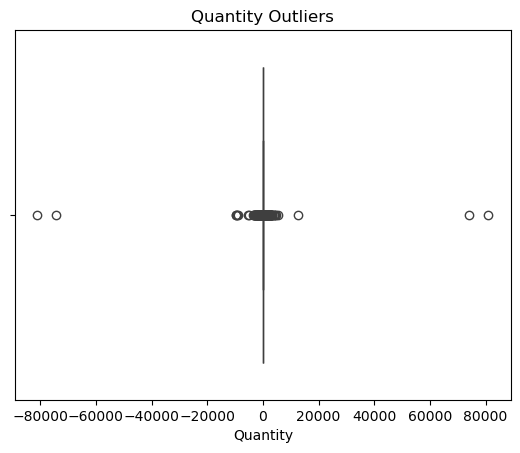

In [45]:
# Checking for outliers in Quantity
sns.boxplot(data=df, x="Quantity")
plt.title("Quantity Outliers")
plt.show()

In [47]:
# Records with extremely large quantities
df[df["Quantity"] > 70000]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom


In [49]:
# Extremely negative quantities
df[df["Quantity"] < -70000]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


##### Quantity Outliers Findings

The boxplot shows quantities ranging from -80,995 to 80,995 units, making smaller values difficult to see. 

After checking quantities above 70,000 and below -70,000, it was found that:

* Customer 12346 ordered 74,215 items and cancelled them about 16 minutes later.
* Customer 16446 ordered 80,995 items and also cancelled them 12 minutes later.

Both customers cancelled their full orders, meaning that no actual sales were made from those orders. 

If cancelled orders are removed but the original purchases are kept, the company may appear to have sold more products than it actually did. This is why cancellations should be included when calculating net revenue.

**Unit Price Outliers**

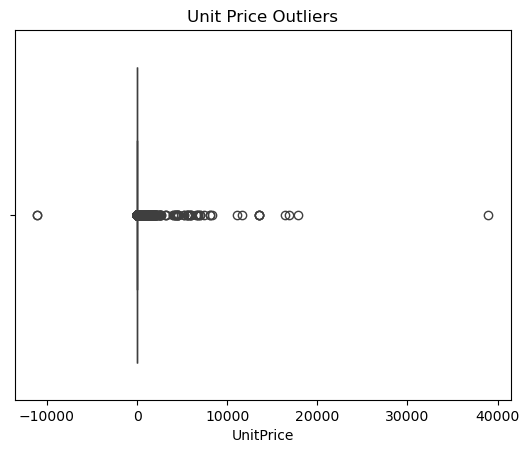

In [73]:
# Checking for outliers in unit price
sns.boxplot(data=df, x="UnitPrice")
plt.title("Unit Price Outliers")
plt.show()

In [75]:
# Investigate negative prices
df[df["UnitPrice"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [77]:
# Investigate extremely high prices
df[df["UnitPrice"] > 10000]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
15016,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom
16232,C537644,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:34:00,13474.79,NaN,United Kingdom
16356,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
524601,C580604,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:35:00,11586.50,NaN,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom


##### Outlier Detection Findings - Unit Price Outliers
The boxplot shows extreme prices ranging from -£11,062.06 to £38,970.

After checking for negative prices and prices above £10,000, the following records were identified:
- Adjust bad debt: Financial adjustments.
- Amazon fees: Charges rather than product sales.
- Manual transactions: Records with unclear product information.

Not all records in the dataset represent product sales. Including these records could lead to misleading revenue and product performance results, so they will be removed during data cleaning.

#### 1.8 Data Cleaning

Before the analysis, it was important that the dataset needed to be cleaned to improve better results. This includes handling duplicates, missing values, unusual transactions and cancelled orders. 


**Creating a Copy and Removing Duplicates**

In [82]:
# Creating a copy of the original dataset
df_clean = df.copy()

In [84]:
# Remove duplicate records
df_clean.drop_duplicates(keep="first", inplace=True)

In [86]:
# Checking remaining duplicates
df_clean.duplicated().sum()

0

In [87]:
# Check the dataset size after removing duplicates
df_clean.shape

(536641, 8)

A copy of the original dataset was created to avoid modifying the original data. A total of 5,268 duplicate records were removed to prevent possible double-counting, leaving 536,641 records.

**Handling Missing Values and Prices**

In [92]:
# Check remaining missing values
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [94]:
# Display records with missing product descriptions
df_clean[df_clean["Description"].isnull()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [96]:
# Check prices of records with missing descriptions
df_clean[df_clean["Description"].isnull()]["UnitPrice"].value_counts()

UnitPrice
0.0    1454
Name: count, dtype: int64

All 1,454 records with missing product descriptions have a unit price of zero. Since the analysis focuses on paid transactions, records with zero or negative prices will have to be removed.

In [99]:
# Keep transactions with positive unit prices
df_clean = df_clean[df_clean["UnitPrice"] > 0]

In [103]:
# Check remaining missing values
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132565
Country             0
dtype: int64

In [105]:
# Dataset size
df_clean.shape

(534129, 8)

After removing records with zero and negative prices, 534,129 records remained, and there were no missing product descriptions.


Records with missing customer IDs were kept because they still provide useful sales information. However, they will not be used for individual customer analysis because we cannot identify who made these purchases.

**Removing Financial and Manual Transactions**

In [115]:
# Check financial and manual transactions
df_clean[df_clean["StockCode"].isin(["AMAZONFEE", "M", "B"])]["Description"].value_counts()

Description
Manual             560
AMAZON FEE          34
Adjust bad debt      1
Name: count, dtype: int64

In [122]:
# Remove financial and manual transactions
df_clean = df_clean[~df_clean["StockCode"].isin(["AMAZONFEE", "M", "B"])]

In [124]:
# Check the dataset size
df_clean.shape

(533534, 8)

A total of 595 records were removed, including Amazon fees, bad debt adjustments and manual transactions with unclear product information.

These records were excluded to avoid including financial charges and unidentified transactions in the product sales analysis.  After this process, 533,534 records remained.

**Handling Cancelled Transactions**

In [138]:
# Check remaining cancelled transactions
df_clean[df_clean["InvoiceNo"].astype(str).str.startswith("C")].shape[0]

8975

In [140]:
# Check remaining negative quantities
df_clean[df_clean["Quantity"] < 0].shape[0]

8975

In [142]:
# Check cancelled transactions with negative quantities
df_clean[(df_clean["InvoiceNo"].astype(str).str.startswith("C")) &
         (df_clean["Quantity"] < 0)].shape[0]

8975

The results confirmed that all 8,975 remaining records with negative quantities were related to cancelled transactions.

Instead of permanently removing these records, two separate datasets will be used for different purposes.

In [145]:
# Keep positive purchase transactions
df_sales = df_clean[df_clean["Quantity"] > 0].copy()

In [147]:
# Check the sales dataset size
df_sales.shape

(524559, 8)

Two datasets are now available for the analysis:
- `df_clean (533,534 records)`: Includes purchases and cancellations, allowing net revenue to be calculated.
- `df_sales (524,559 records)`: Includes positive purchases only to analyse customer purchasing behaviour and gross sales.
  
This approach helps prevent cancelled orders from inflating net revenue calculations.

**Checking Data Types**

In [153]:
# Check data types
df_sales.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

After cleaning, the data types were checked. InvoiceDate is already in the correct date format, and Quantity and UnitPrice are numerical , so no changes are needed.

#### 1.9 Creating New Variables

In [160]:
# Calculate revenue for each record
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

In [170]:
# Get the year and month
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M")

In [172]:
# Get the day of the week
df_clean["Day"] = df_clean["InvoiceDate"].dt.day_name()

In [166]:
# Update the dataset with the new columns
df_sales = df_clean[df_clean["Quantity"] > 0].copy()

In [168]:
# Display the updated dataset
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Day
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday


Three new columns were created to make the analysis easier:
- `Revenue`: Shows the total value of each transaction record.
- `Month`: Helps identify which months have higher or lower sales.
- `Day`: Helps identify which days of the week have more sales.
  
These columns will be used to create the graphs and interactive dashboard.

#### 1.10 Data Preparation Summary

In [179]:
# Comparing the original and cleaned datasets
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Sales dataset:", df_sales.shape)

Original dataset: (541909, 8)
Cleaned dataset: (533534, 11)
Sales dataset: (524559, 11)


In [181]:
# Check final missing values
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132424
Country             0
Revenue             0
Month               0
Day                 0
dtype: int64

The original dataset contained 541,909 records and 8 columns. After cleaning, 8,375 records were removed, and three new columns were added.

A separate dataset with 524,559 positive purchase records was also created.

However, missing customer IDs were kept because they still provide useful sales information, but they will not be used for individual customer analysis.

### 2. Exploratory Data Analysis (EDA)

This section uses different visualisations to understand sales trends, product performance, customer purchasing behaviour and differences between countries.

#### 2.1 Monthly Revenue

In [194]:
# Calculate total revenue for each month
monthly_revenue = df_clean.groupby("Month")["Revenue"].sum()

monthly_revenue

Month
2010-12     786020.600
2011-01     596906.700
2011-02     510794.730
2011-03     696328.600
2011-04     490915.051
2011-05     745555.690
2011-06     739793.190
2011-07     695179.741
2011-08     717729.350
2011-09    1031202.882
2011-10    1084859.980
2011-11    1470245.940
2011-12     462091.250
Freq: M, Name: Revenue, dtype: float64

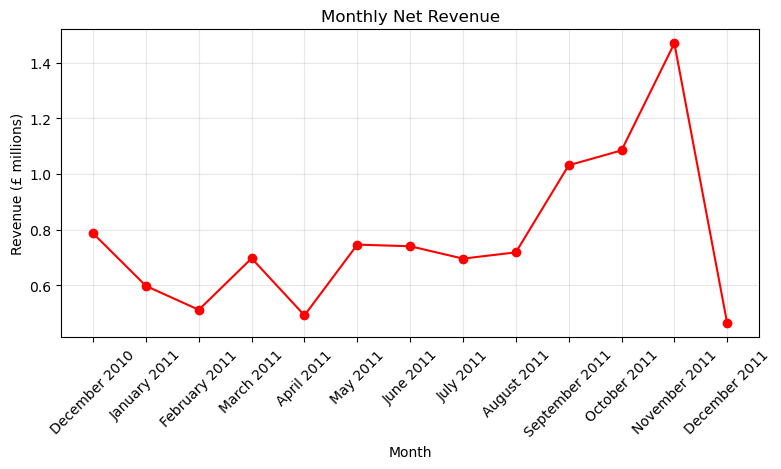

In [212]:
# Plot monthly revenue
plt.figure(figsize=(9, 4))

plt.plot(monthly_revenue.index.strftime("%B %Y"),
         monthly_revenue.values / 1000000,
         color="red", marker="o")

plt.title("Monthly Net Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£ millions)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

**Business Question**: How does monthly revenue change over time, and which months have higher sales?

**Chart Choice**: A line chart was chosen because it clearly shows changes in revenue over time.

**Findings**:
- April 2011 had the lowest revenue when comparing all complete months, around £490,000.
- Revenue remained almost the same between May and August 2011.
- November had the highest revenue, reaching around £1.47 million, more than double August's revenue.
- The increase may be related to Christmas shopping, but more data is needed to confirm this.
- Revenue dropped in December 2011, but the dataset only covers the first nine days of the month, making it difficult to compare with other months.

**Business Recommendation**: The company could prepare more stock before September and plan promotions for the months leading up to Christmas.

In [223]:
df["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')